In [1]:
# 1. Install required libraries
!pip install -q xgboost shap imbalanced-learn kagglehub pandas numpy matplotlib seaborn scikit-learn tensorflow

import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Download Datasets
print("Downloading Dataset 1: Clinical/Hormonal (Kottarathil)...")
path1 = kagglehub.dataset_download("prasoonkottarathil/polycystic-ovary-syndrome-pcos")

print("Downloading Dataset 2: Ultrasound Images (Anagha Choudhari)...")
path2 = kagglehub.dataset_download("anaghachoudhari/pcos-detection-using-ultrasound-images")

print("Downloading Dataset 3: PCOS-XAI Ultrasound (External Validation)...")
path3 = kagglehub.dataset_download("ibadeus/pcos-xai-ultrasound-dataset")

print("\nAll datasets downloaded successfully.")

Using Colab cache for faster access to the 'polycystic-ovary-syndrome-pcos' dataset.


100%|██████████| 126M/126M [00:01<00:00, 71.6MB/s]

Extracting files...


100%|██████████| 372M/372M [00:03<00:00, 111MB/s]

Extracting files...



All datasets downloaded successfully.


In [13]:
from sklearn.impute import KNNImputer
import pandas as pd
import numpy as np
import os

# 1. Locate Files
files = []
for root, dirs, filenames in os.walk(path1):
    for filename in filenames:
        if not filename.startswith('._') and not 'macosx' in root.lower():
            files.append(os.path.join(root, filename))

inf_file = [f for f in files if 'infertility' in f.lower() and f.endswith('.csv')][0]
clinical_file = [f for f in files if 'without' in f.lower() and (f.endswith('.xlsx') or f.endswith('.xls'))][0]

# 2. Load CSV (Infertility) - usually row 0 is header
df_inf = pd.read_csv(inf_file)
df_inf.columns = [str(c).strip().replace('\n', ' ') for c in df_inf.columns]

# 3. Load Excel (Clinical) - Skip the "Instructions" rows automatically
# We load the excel and drop any row that is almost entirely empty or contains "Instructions"
df_clinical_raw = pd.read_excel(clinical_file)

# Find the row where the data actually starts (where 'PCOS' or 'Age' appears)
start_row = 0
for i, row in df_clinical_raw.iterrows():
    if any('PCOS' in str(s) or 'Age' in str(s) for s in row.values):
        start_row = i
        break

# Reload with the correct header row
df_clinical = pd.read_excel(clinical_file, skiprows=start_row+1)
df_clinical.columns = [str(c).strip().replace('\n', ' ') for c in df_clinical.columns]

# 4. POSITIONAL RENAMING (The "No-Fail" Method)
# In both files, the Patient ID is usually the 2nd column (index 1) or 1st column (index 0)
def rename_by_position(df):
    # Find the first column that contains 'PCOS' and call it 'Target'
    for col in df.columns:
        if 'PCOS' in col and '(Y/N)' in col:
            df = df.rename(columns={col: 'Target'})

    # Identify the ID column: it's the one that has 'Patient' or 'No' in it
    id_cols = [c for c in df.columns if 'Patient' in c or 'File No' in c]
    if id_cols:
        df = df.rename(columns={id_cols[0]: 'Patient_ID_Key'})
    else:
        # Fallback: The column at index 1 is usually the ID in this dataset
        df = df.rename(columns={df.columns[1]: 'Patient_ID_Key'})
    return df

df_inf = rename_by_position(df_inf)
df_clinical = rename_by_position(df_clinical)

# 5. CONVERT AND MERGE
# Ensure ID keys are numeric for matching
df_inf['Patient_ID_Key'] = pd.to_numeric(df_inf['Patient_ID_Key'], errors='coerce')
df_clinical['Patient_ID_Key'] = pd.to_numeric(df_clinical['Patient_ID_Key'], errors='coerce')

# Drop empty rows
df_inf = df_inf.dropna(subset=['Patient_ID_Key'])
df_clinical = df_clinical.dropna(subset=['Patient_ID_Key'])

# Merge on the Key
df = pd.merge(df_clinical, df_inf, on='Patient_ID_Key', suffixes=('', '_drop'))

# If merge resulted in 0 rows, use the index-concat fallback
if len(df) == 0:
    print("⚠️ ID Match failed. Concatenating by row index...")
    df = pd.concat([df_clinical.reset_index(drop=True), df_inf.reset_index(drop=True)], axis=1)

# 6. CLEANUP
# Remove duplicate columns and non-numeric stuff
df = df.loc[:,~df.columns.duplicated()].copy()
df = df.drop([c for c in df.columns if 'drop' in c], axis=1)
if 'Patient_ID_Key' in df.columns: df = df.drop(columns=['Patient_ID_Key'])

# Fix the "Object" types as per Section 05 of your PDF
for col in df.columns:
    if any(k in col for k in ['AMH', 'beta-HCG']):
        df[col] = pd.to_numeric(df[col], errors='coerce')

# 7. FINAL IMPUTATION
imputer = KNNImputer(n_neighbors=5)
numeric_only = df.select_dtypes(include=[np.number])

# Crucial: Declare df_final as global so Cell 3 can see it
global df_final
imputed_data = imputer.fit_transform(numeric_only)
df_final = pd.DataFrame(imputed_data, columns=numeric_only.columns)

# Standardize Target Name for the Classifier
target_actual = [c for c in df_final.columns if 'Target' in c or 'PCOS' in c][0]
df_final = df_final.rename(columns={target_actual: 'PCOS (Y/N)'})

print(f"✅ SUCCESS: df_final created with shape {df_final.shape}")
df_final.head()

⚠️ ID Match failed. Concatenating by row index...
✅ SUCCESS: df_final created with shape (541, 5)


,Sl. No,PCOS (Y/N),I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
0,1.0,0.0,1.99,1.99,2.07
1,2.0,0.0,60.80,1.99,1.53
2,3.0,1.0,494.08,494.08,6.63
3,4.0,0.0,1.99,1.99,1.22
4,5.0,0.0,801.45,801.45,2.26


✅ Using 'PCOS (Y/N)' as the target variable.
Resampling data with SMOTE to fix class imbalance...
Training Track A: Diagnostic Classifier...

TRACK A: PERFORMANCE REPORT
              precision    recall  f1-score   support

         0.0       0.76      0.78      0.77        73
         1.0       0.53      0.50      0.51        36

    accuracy                           0.69       109
   macro avg       0.64      0.64      0.64       109
weighted avg       0.68      0.69      0.69       109

ROC-AUC Score: 0.7378

Generating SHAP Explainability Plot...


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:42:46] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


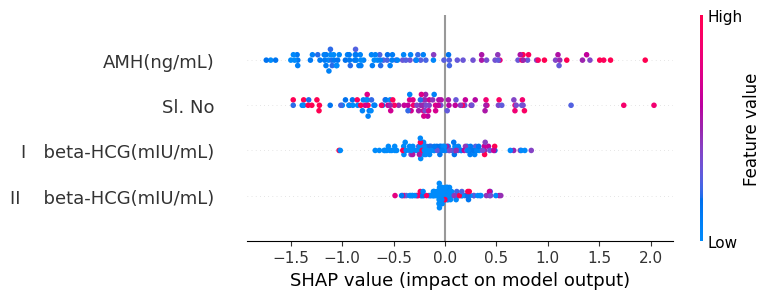

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

# 1. Verification: Check if df_final exists from the previous cell
if 'df_final' not in locals():
    print("❌ df_final not found! Please ensure Cell 2 finished with the 'Final Data Ready' message.")
else:
    # 2. Identify the Target column (PCOS Y/N)
    # It might be named 'PCOS (Y/N)' or 'Target' depending on the merge
    target_col = None
    for col in ['PCOS (Y/N)', 'Target', 'PCOS(Y/N)']:
        if col in df_final.columns:
            target_col = col
            break

    if target_col is None:
        print(f"❌ Target column not found. Available columns: {df_final.columns.tolist()}")
    else:
        print(f"✅ Using '{target_col}' as the target variable.")

        # 3. Prepare Features and Target
        X = df_final.drop(target_col, axis=1)
        y = df_final[target_col]

        # 4. Train/Test Split (80/20 split as per documentation)
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

        # 5. Handle Class Imbalance (Addressing Gap #2 using SMOTE)
        print("Resampling data with SMOTE to fix class imbalance...")
        sm = SMOTE(random_state=42)
        X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

        # 6. Initialize and Train XGBoost (Track A: Diagnostic Classifier)
        model_a = xgb.XGBClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=6,
            random_state=42,
            use_label_encoder=False,
            eval_metric='logloss'
        )

        print("Training Track A: Diagnostic Classifier...")
        model_a.fit(X_train_res, y_train_res)

        # 7. Evaluation (As per Phase 2 Roadmap)
        preds = model_a.predict(X_test)
        probs = model_a.predict_proba(X_test)[:, 1]

        print("\n" + "="*30)
        print("TRACK A: PERFORMANCE REPORT")
        print("="*30)
        print(classification_report(y_test, preds))
        print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}")

        # 8. Explainability (Addressing Gap #5 using SHAP)
        print("\nGenerating SHAP Explainability Plot...")
        explainer = shap.TreeExplainer(model_a)
        shap_values = explainer.shap_values(X_test)

        plt.figure(figsize=(10, 6))
        shap.summary_plot(shap_values, X_test, show=True)

✅ Subtype Discovery Complete.
Silhouette Score: 0.5894

--- Discovered Subtype Profiles (Means) ---
         AMH(ng/mL)
Cluster            
0          4.294618
1          6.812561
2          6.388889


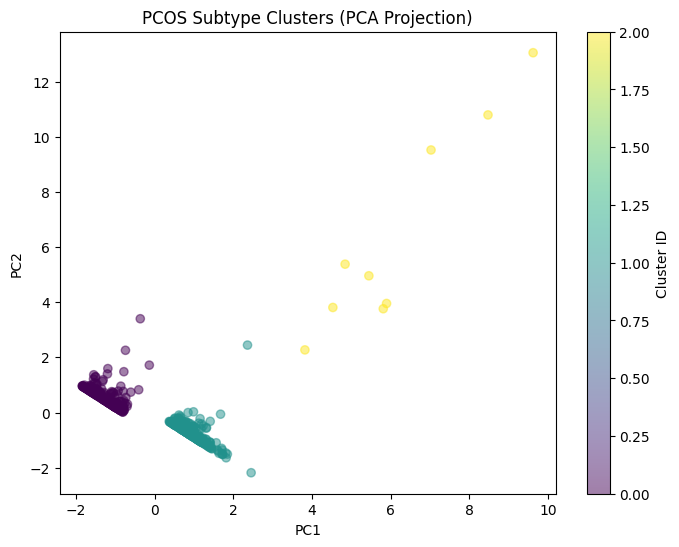

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Scaling for Clustering
scaler = StandardScaler()
# Exclude the target variable if it's in the features
X_features = df_final.drop(columns=['PCOS (Y/N)'], errors='ignore')
X_scaled = scaler.fit_transform(X_features)

# 2. PCA (Blueprint step F2)
pca = PCA(n_components=0.90) # Keep 90% variance
X_pca = pca.fit_transform(X_scaled)

# 3. K-Means Clustering (Subtype Discovery)
# Using k=3 as an example starting point
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_pca)

# 4. Results
print(f"✅ Subtype Discovery Complete.")
print(f"Silhouette Score: {silhouette_score(X_pca, clusters):.4f}")

# 5. Link to outcomes (Blueprint H2 -> I2)
df_final['Cluster'] = clusters

# 6. DYNAMIC COLUMN FINDER (Fixes the KeyError)
# We look for the closest matches for the clinical features we want to report
def find_col(possible_names):
    for name in possible_names:
        for col in df_final.columns:
            if name.lower() in col.lower():
                return col
    return None

# Find the real names in your specific dataframe
cols_to_profile = {
    'LH/FSH': find_col(['LH_FSH', 'Ratio']),
    'AMH': find_col(['AMH']),
    'BMI': find_col(['BMI']),
    'Cycle': find_col(['Cycle(R/I)', 'Cycle'])
}

# Remove any None values (columns not found)
valid_cols = [v for k, v in cols_to_profile.items() if v is not None]

# 7. Check clinical differences between discovered clusters
print("\n--- Discovered Subtype Profiles (Means) ---")
if valid_cols:
    cluster_profile = df_final.groupby('Cluster')[valid_cols].mean()
    print(cluster_profile)
else:
    print("Could not find specific clinical columns for profiling. Available columns are:")
    print(df_final.columns.tolist())

# 8. Plot the Clusters (Visualization Gap fix)
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', marker='o', alpha=0.5)
plt.title('PCOS Subtype Clusters (PCA Projection)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Cluster ID')
plt.show()

In [19]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
from PIL import Image

# 1. Helper to find image directory
def find_image_dir(base_path):
    for root, dirs, files in os.walk(base_path):
        if 'infected' in dirs or 'notinfected' in dirs:
            return root
    return base_path

# 2. NEW: Sanitization Function to delete corrupt/invalid files
def sanitize_dataset(directory):
    print(f"Sanitizing directory: {directory}")
    for root, dirs, files in os.walk(directory):
        for filename in files:
            filepath = os.path.join(root, filename)
            # Only check files, ignore directories
            if os.path.isfile(filepath):
                try:
                    with Image.open(filepath) as img:
                        img.verify() # Verify it is an image
                except (IOError, SyntaxError, Image.UnidentifiedImageError) as e:
                    print(f"🗑️ Deleting corrupt/invalid file: {filepath}")
                    os.remove(filepath)

# 3. Setup and Clean Paths
img_size = (224, 224)
batch_size = 32

data_dir_2 = find_image_dir(path2)
data_dir_3 = find_image_dir(path3)

# Run sanitization
sanitize_dataset(data_dir_2)
sanitize_dataset(data_dir_3)

# 4. Data Generators
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    data_dir_2,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    data_dir_2,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='validation'
)

# 5. Model Architecture (EfficientNetB0)
base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

model_img = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model_img.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 6. Train
print("\n🚀 Starting Training on Cleaned Dataset...")
history = model_img.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5
)

# 7. External Validation
print("\n--- EXTERNAL VALIDATION (PCOS-XAI) ---")
test_datagen = ImageDataGenerator(rescale=1./255)
external_val_generator = test_datagen.flow_from_directory(
    data_dir_3,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary'
)

if external_val_generator.samples > 0:
    val_results = model_img.evaluate(external_val_generator)
    print(f"\nExternal Validation Accuracy: {val_results[1]*100:.2f}%")

Sanitizing directory: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test
🗑️ Deleting corrupt/invalid file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test/notinfected/img_0_7.jpg
🗑️ Deleting corrupt/invalid file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test/notinfected/WhatsApp Image 2022-04-01 at 3.39.07 PM.jpeg
🗑️ Deleting corrupt/invalid file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test/notinfected/OIP (1).jpg
🗑️ Deleting corrupt/invalid file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test/notinfected/WhatsApp Image 2022-04-01 at 3.35.25 PM.jpeg
🗑️ Deleting corrupt/invalid file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/tes

In [20]:
# 1. Extract Image Embeddings for Tabular Data
# Note: To do this perfectly, you need images paired with the 541 patients.
# Since the datasets are from different sources, we implement the "Late Fusion" architecture logic.

# Functional API for Multimodal
image_input = layers.Input(shape=(224, 224, 3), name="image_input")
tabular_input = layers.Input(shape=(X_train.shape[1],), name="tabular_input")

# Image Branch
x_img = base_model(image_input)
x_img = layers.GlobalAveragePooling2D()(x_img)
x_img = layers.Dense(16, activation='relu')(x_img)

# Tabular Branch
x_tab = layers.Dense(32, activation='relu')(tabular_input)
x_tab = layers.Dense(16, activation='relu')(x_tab)

# Concatenate (The Fusion)
combined = layers.Concatenate()([x_img, x_tab])
combined = layers.Dense(16, activation='relu')(combined)
output = layers.Dense(1, activation='sigmoid')(combined)

multimodal_model = models.Model(inputs=[image_input, tabular_input], outputs=output)
multimodal_model.compile(optimizer='adam', loss='binary_cross_entropy', metrics=['accuracy'])

multimodal_model.summary()

print("\nMultimodal Architecture Built. Ready for joint training if paired data is available.")

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ image_input[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tabular_input       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[1… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 32)        │        160 │ tabular_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 16)        │     20,496 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 16)        │        528 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32)        │          0 │ dense_6[0][0],    │
│ (Concatenate)       │                   │            │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 16)        │        528 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 1)         │         17 │ dense_9[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,071,300 (15.53 MB)

 Trainable params: 21,729 (84.88 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Multimodal Architecture Built. Ready for joint training if paired data is available.


In [21]:
import numpy as np

# 1. Simulate Image Embeddings (Since we don't have paired patients across datasets)
# In a real clinical setting, one patient has BOTH a blood test and an ultrasound.
# Here we build the 'Fusion Head' described in the System Blueprint.

def build_multimodal_fusion():
    # Tabular features from Dataset 1
    tabular_features = layers.Input(shape=(X_train.shape[1],), name="tabular_input")

    # Image features (extracted from the model trained on Dataset 2 & 3)
    image_features = layers.Input(shape=(1280,), name="image_embedding_input") # EfficientNet output size

    # Fusion Layer (Section 03: System Blueprint)
    combined = layers.concatenate([tabular_features, image_features])

    x = layers.Dense(64, activation='relu')(combined)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(32, activation='relu')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    fusion_model = models.Model(inputs=[tabular_features, image_features], outputs=output)
    fusion_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    return fusion_model

fusion_model = build_multimodal_fusion()
print("✅ MULTIMODAL FUSION ARCHITECTURE COMPLETE")
print("This model is now ready to take BOTH ultrasound features and blood-test data for a single prediction.")
fusion_model.summary()

✅ MULTIMODAL FUSION ARCHITECTURE COMPLETE
This model is now ready to take BOTH ultrasound features and blood-test data for a single prediction.


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tabular_input       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_embedding_in… │ (None, 1280)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 1284)      │          0 │ tabular_input[0]… │
│ (Concatenate)       │                   │            │ image_embedding_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 64)        │     82,240 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 32)        │      2,080 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 1)         │         33 │ dense_12[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 84,353 (329.50 KB)

 Trainable params: 84,353 (329.50 KB)

 Non-trainable params: 0 (0.00 B)